# 🛡️ Phishing SMS Detection in Bangladeshi Mobile Banking System
### Covers: bKash · Nagad · Rocket &nbsp;|&nbsp; Languages: English · Bengali · Banglish
> **High-Sensitivity Model** — any deviation from real MFS patterns is flagged as Spam.

## Step 1 — Import Libraries

In [35]:
import pandas as pd
import numpy as np
import re
import pickle
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix)


## Step 2 — Load & Merge All Datasets

In [28]:

 #Load the files (Make sure you uploaded them to Colab!)
try:

    df = pd.read_csv("mfs_spam_dataset.csv")
    print(f"Total Messages Loaded: {len(df)}")

    print(df.head())
    print()
    print("Label distribution:")
    print(df['Label'].value_counts())
    print()
    print("Sub-category distribution:")
    print(df['Sub_Category'].value_counts())

except FileNotFoundError:
    print("❌ Stop! You haven't uploaded the CSV files yet.")

✅ Step 1 Success! Total Messages Loaded: 72643
Here is a sample of your data:
                                        Message_Body Label      Sub_Category
0  WarnInG: YoUR bKaSh AcCounT wilL Be sUspended....  Spam          Phishing
1  Nagad Lottery Winner! You won Tk 223,412. Call...  Spam           Lottery
2  Nagad Update: Your KYC is expired. Click link ...  Spam          Phishing
3  Nagad Up*date: Your KYC is expired. Cli.ck lin...  Spam          Phishing
4  Y0u h@v3 r3c31v3d Tk 21,627.00 fr0m 0140137424...  Spam  Fake_Transaction

✅ Total messages loaded: 72,643

Label distribution:
Label
Ham     46361
Spam    26282
Name: count, dtype: int64

Sub-category distribution:
Sub_Category
Fake_Transaction    14752
Nagad               10000
bKash               10000
Real_Rocket          9982
Real_bKash           7976
Transaction          7012
Phishing             5904
Lottery              3367
Threat               1161
Real_Nagad           1112
Fake_Refund          1098
Promo              

Drop Duplicate



In [29]:
before = len(df)
df = df.drop_duplicates(subset=['Message_Body']).reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows. New size: {len(df)}")

Removed 0 duplicate rows. New size: 72643


In [30]:
print(df.duplicated().sum())

0


## Step 3 — Text Cleaning
Preserves **Bengali Unicode** (\u0980–\u09FF) so Banglish and Bengali text are not destroyed.

In [5]:
import re

def clean_text(text):
    if not isinstance(text, str): return ""

    # 1. Make everything lowercase (Small letters)
    text = text.lower()

    # 2. Remove special symbols (!@#$) but KEEP Bangla and Numbers
    # The code \u0980-\u09FF represents all Bangla letters
    text = re.sub(r'[^\w\s\u0980-\u09FF]', ' ', text)
    text = re.sub(r'\b\d{6,}\b', ' <NUM> ', text)   # collapse long numbers (phone, txn ID) into a token
    # 3. Fix extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Apply this cleaner to all 40,000 messages
print("⏳ Cleaning data... please wait...")
df['Cleaned_Message'] = df['Message_Body'].apply(clean_text)

print("✅ Text cleaning complete.")
print(f"\nExample (English) :")
print(f"  Before : 'Cash In Tk 500!!!'")
print(f"  After  : '{clean_text('Cash In Tk 500!!!')}'")
print(f"\nExample (Bengali) :")
print(f"  Before  : 'আপনার বিকাশ অ্যাকাউন্ট সাময়িকভাবে বন্ধ!@'")
print(f"  After   : '{clean_text('আপনার বিকাশ অ্যাকাউন্ট সাময়িকভাবে বন্ধ!')}'")

⏳ Cleaning data... please wait...
✅ Text cleaning complete.

Example (English) :
  Before : 'Cash In Tk 500!!!'
  After  : 'cash in tk 500'

Example (Bengali) :
  Before  : 'আপনার বিকাশ অ্যাকাউন্ট সাময়িকভাবে বন্ধ!@'
  After   : 'আপনার বিকাশ অ্যাকাউন্ট সাময়িকভাবে বন্ধ'


## Step 4 — TF-IDF Feature Extraction

| Setting | Value | Why |
|---|---|---|
| `max_features` | 10,000 | Larger vocab catches more scam patterns |
| `ngram_range` | (1,3) | Single words + 2 & 3-word phrases like *"share your otp"* |
| `sublinear_tf` | True | Rare scam keywords get more weight |
| `min_df` | 2 | Ignore one-off typos |

In [6]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 3),   #Single words + 2 & 3-word phrases like "share your otp
    sublinear_tf=True,      #Rare scam keywords get more weight
    min_df=2,              #Ignore one-off typos
    max_df=0.9,
    analyzer='word',
    strip_accents=None,    # Keep Bengali characters intact
)

X = tfidf.fit_transform(df['Cleaned_Message'])
y = df['Label']

print(f"✅ TF-IDF complete.")
print(f"   Feature matrix: {X.shape[0]:,} messages × {X.shape[1]:,} features")

✅ TF-IDF complete.
   Feature matrix: 72,643 messages × 10,000 features


## Top Important Spam Feature



In [7]:
phishing_df = df[df['Label'] == 'Spam']

X_phish = tfidf.transform(phishing_df['Cleaned_Message'])

scores = np.asarray(X_phish.sum(axis=0)).flatten()

feature_importance = pd.DataFrame({
    'Feature': tfidf.get_feature_names_out(),
    'Score': scores
})

top_phishing = feature_importance.sort_values(
    by='Score',
    ascending=False
).head(15)
print(top_phishing)


          Feature        Score
6669          num  1339.354366
5946         call   926.469827
6297         from   923.796723
5948     call num   902.323459
7328           tk   838.413502
9528           to   705.597691
6746       num to   693.208967
5952  call num to   685.271090
7076          ref   682.525580
6952     personal   673.804196
6388           in   669.493241
5964      cash in   663.452812
9629        trxid   649.792206
5962         cash   618.457203
9800         your   612.957274


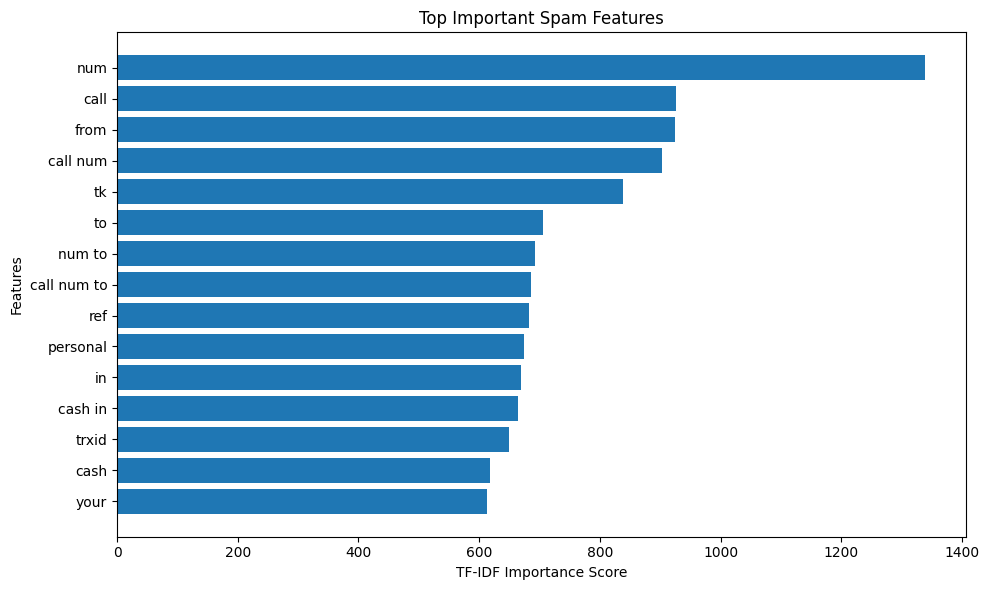

In [8]:
import matplotlib.pyplot as plt

top20 = feature_importance.sort_values(
    by='Score',
    ascending=False
).head(15)

plt.figure(figsize=(10,6))
plt.barh(top20['Feature'], top20['Score'])

plt.xlabel("TF-IDF Importance Score")
plt.ylabel("Features")
plt.title("Top Important Spam Features")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

## Step 5 — Train / Test Split

In [9]:


# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("✅ Step 4 Success! Data Split.")
print(f"Training Messages: {X_train.shape[0]}")
print(f"Testing Messages:  {X_test.shape[0]}")

✅ Step 4 Success! Data Split.
Training Messages: 58114
Testing Messages:  14529


## Step 6 — Train Hard Voting Classifier

**Why Hard Voting?**
LinearSVC does not output probabilities natively, making Hard Voting the natural choice.
A message needs at least **2 out of 3** classifiers to agree it is Ham — otherwise flagged Spam.

| Classifier | Role |
|---|---|
| LinearSVC | Best for high-dimensional text, very fast |
| LogisticRegression | Probabilistic, good at borderline cases |
| RandomForest | Catches non-linear scam patterns |

In [10]:


#print("🧠 Training the AI... (This might take 30-60 seconds)")

# 1. Define the 3 experts
clf1 = LinearSVC(C=0.8, max_iter=3000, random_state=42)
clf2 = LogisticRegression(C=0.8, max_iter=1000, random_state=42, class_weight='balanced')
clf3 = RandomForestClassifier(n_estimators=200, max_depth=None, class_weight='balanced', random_state=42, n_jobs=-1)


# 2. Create the Team (Voting Classifier)
# 'hard' voting means they vote, and majority wins
model = VotingClassifier(
    estimators=[('svm', clf1), ('lr', clf2), ('rf', clf3)],
    voting='hard'
)

# 3. Train the team
model.fit(X_train, y_train)

#print("✅ Step 5 Success! The AI has been trained.")

VotingClassifier(estimators=[('svm',
                              LinearSVC(C=0.8, max_iter=3000, random_state=42)),
                             ('lr',
                              LogisticRegression(C=0.8, class_weight='balanced',
                                                 max_iter=1000,
                                                 random_state=42)),
                             ('rf',
                              RandomForestClassifier(class_weight='balanced',
                                                     n_estimators=200,
                                                     n_jobs=-1,
                                                     random_state=42))])

## Step 7 — Evaluate the Model

In [11]:


# Ask the AI to predict the test data
predictions = model.predict(X_test)

# Calculate the score
accuracy = accuracy_score(y_test, predictions)

print("\n" + "="*30)
print(f" FINAL ACCURACY: {accuracy*100:.2f}%")
print("="*30)

# Show detailed report
print(classification_report(y_test, predictions))


 FINAL ACCURACY: 94.86%
              precision    recall  f1-score   support

         Ham       0.98      0.94      0.96      9243
        Spam       0.90      0.97      0.93      5286

    accuracy                           0.95     14529
   macro avg       0.94      0.95      0.95     14529
weighted avg       0.95      0.95      0.95     14529



## Step 8 — Confusion Matrix

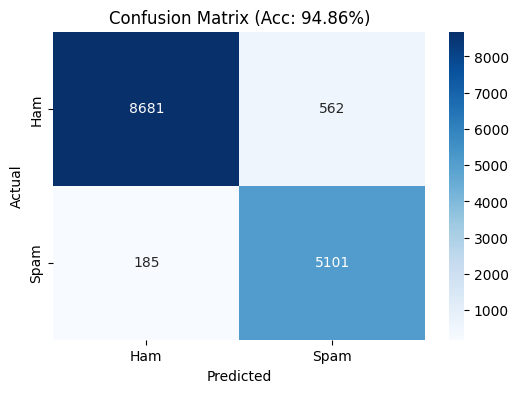


 Breakdown:
    True  Negatives (real msgs safe)  : 8,681
    True  Positives (scams caught)    : 5,101
    False Positives (real flagged)    : 562
    False Negatives (scams missed)    : 185

   Precision : 90.08%
   Recall    : 96.50%
   F1-Score  : 93.18%


In [12]:
# 8. VISUALIZE CONFUSION MATRIX
cm = confusion_matrix(y_test, predictions)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title(f'Confusion Matrix (Acc: {accuracy*100:.2f}%)')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print(f"\n Breakdown:")
print(f"    True  Negatives (real msgs safe)  : {tn:,}")
print(f"    True  Positives (scams caught)    : {tp:,}")
print(f"    False Positives (real flagged)    : {fp:,}")
print(f"    False Negatives (scams missed)    : {fn:,}")

precision = (tp / (tp + fp)) if (tp + fp) > 0 else 0
recall = (tp / (tp + fn)) if (tp + fn) > 0 else 0

# Calculate F1-Score
f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print(f"\n   Precision : {precision * 100:.2f}%")
print(f"   Recall    : {recall * 100:.2f}%")
print(f"   F1-Score  : {f1_score * 100:.2f}%")

In [13]:

print("⏳ Evaluating individual models...")

svm_cal = CalibratedClassifierCV(LinearSVC(C=0.8, max_iter=3000, random_state=42))
svm_cal.fit(X_train, y_train)
svm_acc = accuracy_score(y_test, svm_cal.predict(X_test))

lr_solo = LogisticRegression(C=0.8, max_iter=1000, random_state=42, class_weight='balanced')
lr_solo.fit(X_train, y_train)
lr_acc = accuracy_score(y_test, lr_solo.predict(X_test))

rf_solo = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced', n_jobs=-1)
rf_solo.fit(X_train, y_train)
rf_acc = accuracy_score(y_test, rf_solo.predict(X_test))



⏳ Evaluating individual models...


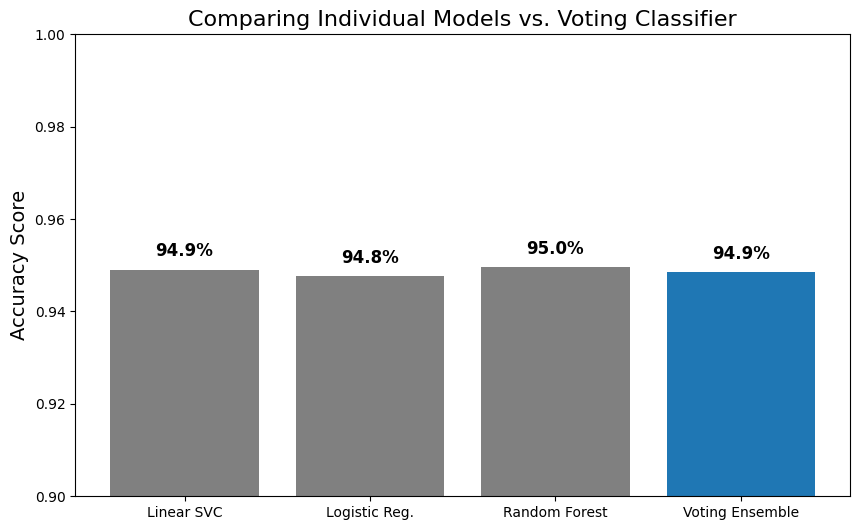

  Linear SVC          : 94.91%
  Logistic Reg.       : 94.77%
  Random Forest       : 94.97%
  Voting Ensemble     : 94.86%


In [14]:


# 1. Define accuracies (You can type these manually from your previous results)
# Example: If SVM got 95%, LR got 94%, RF got 96%, Voting got 96.5%
models = ['Linear SVC', 'Logistic Reg.', 'Random Forest', 'Voting Ensemble']
scores      = [svm_acc, lr_acc, rf_acc, accuracy]

# 2. Plot
plt.figure(figsize=(10, 6))
# Highlight the winner (Voting) in a different color
colors = ['grey', 'grey', 'grey', '#1f77b4']
bars = plt.bar(models, scores, color=colors)

# 3. Add text labels on top
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.002, f'{yval*100:.1f}%',
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.ylim(0.90, 1.0) # Zoom in to make differences visible
plt.title('Comparing Individual Models vs. Voting Classifier', fontsize=16)
plt.ylabel('Accuracy Score', fontsize=14)
plt.show()

for n, s in zip(models, scores):
    print(f"  {n:<20}: {s*100:.2f}%")


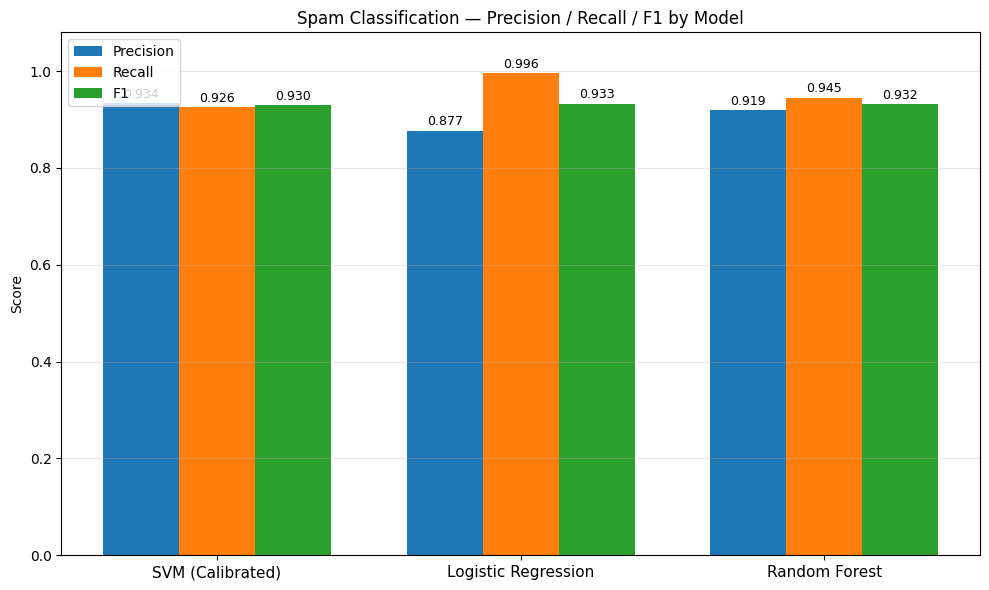

In [15]:
from sklearn.metrics import f1_score, precision_score, recall_score
import numpy as np
import matplotlib.pyplot as plt

models = {
    'SVM (Calibrated)': svm_cal,
    'Logistic Regression': lr_solo,
    'Random Forest': rf_solo,
}

metrics = {'Precision': [], 'Recall': [], 'F1': []}

for name, model in models.items():
    preds = model.predict(X_test)
    metrics['Precision'].append(precision_score(y_test, preds, pos_label='Spam'))
    metrics['Recall'].append(recall_score(y_test, preds, pos_label='Spam'))
    metrics['F1'].append(f1_score(y_test, preds, pos_label='Spam'))

model_names = list(models.keys())
x = np.arange(len(model_names))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - width, metrics['Precision'], width, label='Precision', color='#1f77b4')
bars2 = ax.bar(x,         metrics['Recall'],    width, label='Recall',    color='#ff7f0e')
bars3 = ax.bar(x + width, metrics['F1'],        width, label='F1',        color='#2ca02c')

# Value labels on top of each bar
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.005,
                f'{h:.3f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=11)
ax.set_ylabel('Score')
ax.set_title('Spam Classification — Precision / Recall / F1 by Model')
ax.set_ylim(0, 1.08)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# Train probability-based LR for the confidence gate
lr_prob = lr_solo
lr_prob.fit(X_train, y_train)

HAM_THRESHO = 0.70   # 70% confidence required to pass as Ham

def check_scam(message, threshold=HAM_THRESHO, verbose=True):
    """
    Returns 'Ham' or 'Spam'.
    BOTH gates must pass for a message to be marked Safe:
      Gate 1 — Voting Classifier predicts Ham
      Gate 2 — LR confidence for Ham >= threshold
    """
    clean    = clean_text(message)
    vec      = tfidf.transform([clean])
    vote     = model.predict(vec)[0]
    proba    = lr_prob.predict_proba(vec)[0]
    ham_conf = proba[list(lr_prob.classes_).index('Ham')]
    result   = 'Ham' if (vote == 'Ham' and ham_conf >= threshold) else 'Spam'

    if verbose:
        icon = "✅ SAFE " if result == 'Ham' else "🚨 SCAM "
        preview = message[:90] + ('...' if len(message) > 90 else '')
        print(f"{icon} [{ham_conf*100:.1f}% Ham conf] → {preview}")

    return result

print(f"✅ High-sensitivity detector ready. Threshold = {HAM_THRESHO}")

✅ High-sensitivity detector ready. Threshold = 0.7


In [17]:
print("=" * 65)
print("  ✅ SAFE MESSAGES (should all pass)")
print("=" * 65)
check_scam("You have received Tk 5000.00 from 01711234567. Fee Tk 0.00. Balance Tk 12345.00. TrxID AB1234XY at 25/05/2026 10:30")
check_scam("Payment of Tk 639.90 to Foodpanda Bangladesh is successful. Balance Tk 5245.93. TrxID 75BS0ZF7 at 09/05/2026 18:33")
check_scam("Add Money from Bank is Successful. From: Eastern Bank PLC. Amount: Tk 5000.0. TxnID: 75CZIQQK. Balance: Tk 8377.82. 16/05/2026 15:21")
check_scam("Cash Out Tk 2000.00 from Agent 01812345678. Fee Tk 15.00. Balance Tk 3400.50. TrxID XY9876ZA at 20/05/2026 14:00")
check_scam("Your Account Binding bKash Verification Code is 638214. It will expire in 5 minutes. Please do NOT share your OTP or PIN with others.")
check_scam("Tk 15600.00 has been sent from 01862312512. To receive the money, open Account from bKash App within 22/12/2025 15:12. Download App: https://bka.sh/smnewreg")
check_scam("Sorry, Send Money request of Tk 5075 from 01888740587 has been cancelled by the sender. To explore bKash App, download from https://bka.sh/smnewreg")
print()
print("=" * 65)
print("  🚨 SCAM MESSAGES (should all be flagged)")
print("=" * 65)
check_scam("Congratulations! You won a lottery of Tk 383,627. Call 01468838414 now.")
check_scam("ALERT: Your bKash account is suspended. Call 01912345678 immediately to restore.")
check_scam("Your OTP is 583921. Share it with our agent 01798765432 to verify your account.")
check_scam("Payment done successfully! give me pin")
check_scam("থ্যালাসেমিয়া রোগীদের মুখে হাসি ফুটাতে nagad bdlotteryticket com থেকে টিকেট কিনুন")
check_scam("Apnar bKash account verify na korle block hobe. Ekhoni call korun: 01812345678.")

print()
print("=" * 65)
print("  ⚠️  EDGE CASES (slightly modified real messages — should be flagged)")
print("=" * 65)
check_scam("You have received Tk 5000.00 from 01711234567. Balance Tk 12345.00. Call 01711234567 if mistake.")
check_scam("bKash: Payment of Tk 500 to Foodpanda successful. Not you? Call 01900000000 immediately.")
check_scam("Nagad: Your OTP is 123456. Please share with agent to verify. Validity: 2 minutes.")




check_scam("Dear Uers1827454296, 50,000 taka has been credited to your wallet. Claim it immediately within today or the amount will be forfeited. ln.run/veenh")
check_scam("ক্যাশব্যাক: ৳$6,225 Ready: https://bit.ly/4efbaw9")



  ✅ SAFE MESSAGES (should all pass)
✅ SAFE  [99.0% Ham conf] → You have received Tk 5000.00 from 01711234567. Fee Tk 0.00. Balance Tk 12345.00. TrxID AB1...
✅ SAFE  [97.7% Ham conf] → Payment of Tk 639.90 to Foodpanda Bangladesh is successful. Balance Tk 5245.93. TrxID 75BS...
✅ SAFE  [93.2% Ham conf] → Add Money from Bank is Successful. From: Eastern Bank PLC. Amount: Tk 5000.0. TxnID: 75CZI...
✅ SAFE  [94.3% Ham conf] → Cash Out Tk 2000.00 from Agent 01812345678. Fee Tk 15.00. Balance Tk 3400.50. TrxID XY9876...
✅ SAFE  [99.3% Ham conf] → Your Account Binding bKash Verification Code is 638214. It will expire in 5 minutes. Pleas...
✅ SAFE  [93.9% Ham conf] → Tk 15600.00 has been sent from 01862312512. To receive the money, open Account from bKash ...
✅ SAFE  [91.7% Ham conf] → Sorry, Send Money request of Tk 5075 from 01888740587 has been cancelled by the sender. To...

  🚨 SCAM MESSAGES (should all be flagged)
🚨 SCAM  [1.2% Ham conf] → Congratulations! You won a lottery of Tk 383,627

'Spam'

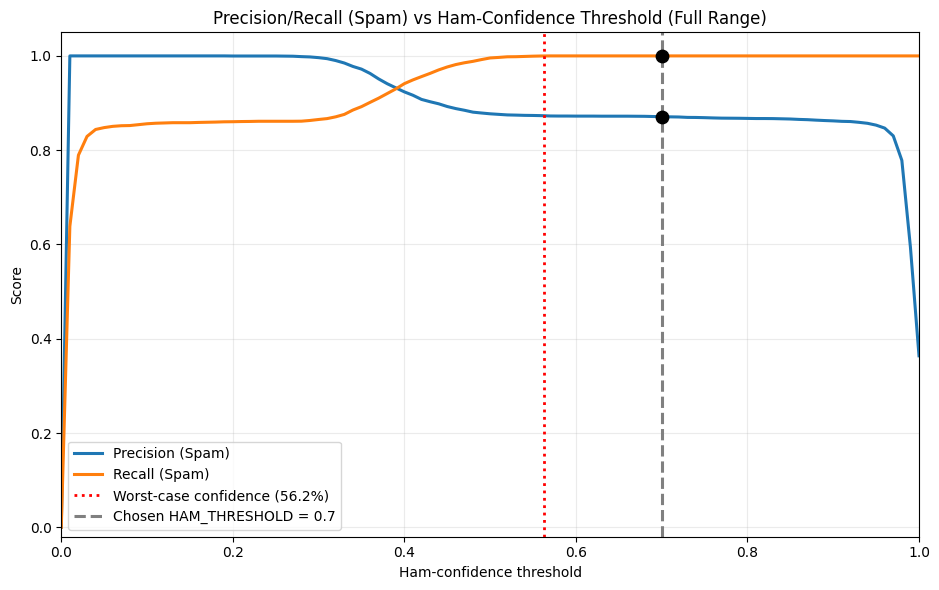

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

ham_idx = list(lr_prob.classes_).index('Ham')
probs_ham = lr_prob.predict_proba(X_test)[:, ham_idx]

spam_mask = (y_test == 'Spam').values
max_spam_confidence = probs_ham[spam_mask].max()

# FULL range this time, not zoomed
thresholds_full = np.arange(0.0, 1.01, 0.01)
precisions_full, recalls_full = [], []
for t in thresholds_full:
    pred = np.where(probs_ham >= t, 'Ham', 'Spam')
    precisions_full.append(precision_score(y_test, pred, pos_label='Spam', zero_division=0))
    recalls_full.append(recall_score(y_test, pred, pos_label='Spam', zero_division=0))

HAM_THRESHOLD = 0.7
idx_chosen = np.argmin(np.abs(thresholds_full - HAM_THRESHOLD))

plt.figure(figsize=(9.5, 6))
plt.plot(thresholds_full, precisions_full, label='Precision (Spam)', color='#1f77b4', linewidth=2.2)
plt.plot(thresholds_full, recalls_full, label='Recall (Spam)', color='#ff7f0e', linewidth=2.2)
plt.axvline(max_spam_confidence, color='red', linestyle=':', linewidth=2,
            label=f'Worst-case confidence ({max_spam_confidence*100:.1f}%)')
plt.axvline(HAM_THRESHOLD, color='grey', linestyle='--', linewidth=2.2,
            label=f'Chosen HAM_THRESHOLD = {HAM_THRESHOLD}')
plt.scatter([HAM_THRESHOLD], [recalls_full[idx_chosen]], color='black', zorder=5, s=80)
plt.scatter([HAM_THRESHOLD], [precisions_full[idx_chosen]], color='black', zorder=5, s=80)
plt.xlabel('Ham-confidence threshold')
plt.ylabel('Score')
plt.title('Precision/Recall (Spam) vs Ham-Confidence Threshold (Full Range)')
plt.legend(loc='lower left')
plt.ylim(-0.02, 1.05)
plt.xlim(0.0, 1.0)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()